# Topological-string resurgence

The topological string is a good setting for resurgence: its perturbative expansion
is *known in closed form* for a couple of geometries, the divergence is factorial,
and the objects the divergence predicts are D-branes. This notebook takes the two
closed forms, runs the whole `Resurgence.jl` pipeline on them, and checks every
step against an exact identity.

**Scope.** `Resurgence.jl` is a *consumer* here. It never computes a
Gromov-Witten or Gopakumar-Vafa invariant, never runs topological recursion, and
never runs the holomorphic-anomaly recursion. Everything below starts from a
quoted closed form, or would start from an imported table. That boundary is
deliberate and permanent; see the last section.

**Prerequisites.** Some complex analysis and the idea of an asymptotic series.
No algebraic geometry: section 1 says what a topological-string free energy is in
enough detail to follow the rest, and every geometric input is stated rather than
derived.

## 1. What a topological-string free energy is

Fix a Calabi-Yau threefold $X$: a complex three-dimensional space with a
nowhere-vanishing holomorphic volume form. The topological A-model on $X$ counts
holomorphic maps from a Riemann surface into $X$. Organising those counts by the
genus $g$ of the surface and by the homology class $\beta \in H_2(X,\mathbb{Z})$
of its image gives the **Gromov-Witten invariants** $N_{g,\beta} \in \mathbb{Q}$,
and packaging them by genus gives the **genus-$g$ free energy**

$$ F_g(t) \;=\; \sum_{\beta} N_{g,\beta}\, Q^{\beta}, \qquad Q^{\beta} = e^{-\beta\cdot t} , $$

where $t$ is the complexified Kähler parameter (the "size" of the curve classes;
$Q = e^{-t}$ is small when $X$ is large). The **total free energy** is the genus
expansion in the string coupling $\lambda$:

$$ F(\lambda, t) \;=\; \sum_{g \ge 0} \lambda^{2g-2}\, F_g(t), \qquad
   Z_{\text{top}} = e^{F} . $$

Three facts are all we need.

1. **The genus expansion is asymptotic, not convergent.** $F_g$ grows like
   $(2g)!$, so the sum over $g$ has zero radius of convergence in $\lambda$. This
   is not a technical nuisance. It says that the perturbative topological string is
   incomplete, and that the missing content is nonperturbative, of size
   $e^{-A/\lambda}$.

2. **Resurgence turns the divergence into that missing content.** The Borel
   transform of $F$ in $\lambda$ has singularities at definite points $A$ of the
   Borel plane, and each one is the *action* of a nonperturbative effect. In the
   topological string those actions are $2\pi i$ times periods, that is, central
   charges of D-branes wrapping cycles of $X$, and the strength of each
   singularity counts the BPS states with that charge. The large-order behaviour
   of $N_{g,\beta}$ therefore knows about the brane spectrum.

3. **The $F_g$ are somebody else's job.** For a general $X$ they come from the
   holomorphic-anomaly recursion, topological vertex, or localisation. Two
   geometries are exceptions, and those are the two below.

Gopakumar and Vafa reorganised the rational $N_{g,\beta}$ into integers
$n^g_\beta$ (counts of BPS states of an M-theory compactification) via a universal
multicover formula. For a geometry whose only nonzero invariant is
$n^0_{\beta_0} = 1$ that formula collapses to something we can expand by hand,
which is exactly what makes the resolved conifold tractable.

In [1]:
using Resurgence
using CairoMakie
using QuadGK: quadgk

CairoMakie.activate!(type = "png")
set_theme!(theme_light(); fontsize = 14)

## 2. Two geometries with closed-form free energies

### 2a. The resolved conifold

The conifold singularity $xy - zw = 0$ in $\mathbb{C}^4$ can be smoothed by
blowing up a $\mathbb{P}^1$; the result is the **resolved conifold**
$X = \mathcal{O}(-1) \oplus \mathcal{O}(-1) \to \mathbb{P}^1$. It is noncompact and
has a single curve class, that $\mathbb{P}^1$, with one Gopakumar-Vafa invariant

$$ n^0_1 = 1, \qquad \text{all others zero.} $$

That single integer is the *only* enumerative input in this notebook. The
Gopakumar-Vafa multicover formula then gives the all-genus answer in closed form,

$$ F(\lambda, t) \;=\; \sum_{d \ge 1} \frac{Q^d}{d\,\bigl(2\sin(d\lambda/2)\bigr)^2},
   \qquad Q = e^{-t}, $$

where the sum over $d$ is the sum over $d$-fold covers of the $\mathbb{P}^1$.
Expanding $1/(2\sin(x/2))^2$ in powers of $x$ and collecting genus by genus,

$$ \boxed{\;F_g(t) \;=\; (-1)^{g-1}\,\frac{B_{2g}}{2g\,(2g-2)!}\;
   \mathrm{Li}_{3-2g}(Q)\;}\qquad (g \ge 2), $$

with $B_{2g}$ the Bernoulli numbers. For $g \ge 2$ the polylogarithm has index
$3-2g \le -1$, and $\mathrm{Li}_{-n}(Q)$ is a *rational function* of $Q$. So for
rational $Q$ every $F_g$ is an exact rational number, and the whole pipeline can
run without ever leaving $\mathbb{Q}$ until the last step.

### 2b. The conifold gap

Now let the $\mathbb{P}^1$ shrink, $t \to 0$. Since
$\mathrm{Li}_{-n}(e^{-t}) \sim n!/t^{n+1}$, the free energies blow up in a very
specific way:

$$ F_g(t) \;\longrightarrow\; (-1)^{g-1}\,\frac{B_{2g}}{2g\,(2g-2)}\; t^{2-2g} . $$

This is the **conifold gap**. Its importance is that it is *universal*: near a
conifold point of **any** Calabi-Yau, compact or not, with $t$ the flat coordinate
vanishing there, the leading singular behaviour of $F_g$ is exactly this, with no
subleading poles in between (hence "gap"). Huang, Klemm and Quackenbush turned
that into the boundary condition that fixes the holomorphic-anomaly recursion on
compact Calabi-Yaus. The same series is also the $c=1$ string at self-dual radius.

We take the version without the sign,

$$ F^{\text{gap}}_g(t) \;=\; \frac{B_{2g}}{2g(2g-2)}\, t^{2-2g}, $$

so that the resolved conifold's own $t \to 0$ limit is this series at $t \mapsto i t$
(because $i^{2-2g} = (-1)^{g-1}$). The two conventions differ only by where the
Borel singularities sit: on the imaginary axis for the first, on the real axis for
the second.

In [2]:
# Exact rational coefficients, genus 2 through 7. Both live on the unit λ grid with
# power offset 2, so the coefficient of λ^{2g-2} is F_g and the odd slots are zero.
gap = conifold_gap_series(6)              # t = 1
rc  = resolved_conifold_series(6; Q = 1//4)

println("conifold gap,   F_2 … F_7 :")
foreach(c -> println("   ", c), coefficients(gap)[1:2:end])
println()
println("resolved conifold at Q = 1/4, F_2 … F_7 :")
foreach(c -> println("   ", c), coefficients(rc)[1:2:end])

conifold gap,   F_2 … F_7 :


   -1//240
   1//1008
   -1//1440
   1//1056
   -691//327600
   1//144

resolved conifold at Q = 1/4, F_2 … F_7 :
   1//540
   11//40824
   1027//10497600
   67337//969978240
   1743227851//21665786688000
   1299571793//9428188492800


In [3]:
# The gap really is the Q → 1 limit: (1-Q)^{2g-2} F_g^{RC}(Q) → (-1)^{g-1} F_g^{gap}(1).
Q = big(1) - big(10)^-10
lim = coefficients(resolved_conifold_series(5; Q))[1:2:end] .*
      [(1 - Q)^(2g - 2) for g in 2:6]
tgt = [(isodd(g) ? 1 : -1) * coefficients(gap)[2g - 3] for g in 2:6]
[Float64.(lim) Float64.(tgt)]

5×2 Matrix{Float64}:
 0.00416667   0.00416667
 0.000992063  0.000992063
 0.000694444  0.000694444
 0.00094697   0.00094697
 0.00210928   0.00210928

## 3. Reading the instanton action off the coefficients

Using $B_{2g} \sim (-1)^{g+1} 2\,(2g)!/(2\pi)^{2g}$ and
$\mathrm{Li}_{3-2g}(e^{-t}) \sim (2g-3)!/t^{2g-2}$,

$$ F_g \;\sim\; \frac{2(2g-1)\,(2g-3)!}{(2\pi t)^{2g}}\, t^{2}, $$

which in the variable $\lambda$ (where $F_g$ sits at $\lambda^{2g-2}$) is ordinary
Gevrey-1 factorial growth $a_n \sim S\,\Gamma(n+b)/A^n$ with

$$ |A| \;=\; 2\pi t . $$

One bookkeeping subtlety is the single design decision in this layer. The free
energy has only *even* powers of $\lambda$, and we store it on the **unit**
$\lambda$ grid with the odd coefficients exactly zero, rather than as a series in
$x = \lambda^2$. Two consequences:

* In $x$ the coefficients grow like $\Gamma(2g)$, i.e. Gevrey-2, and nothing about
  the Borel transform closes. On the unit $\lambda$ grid the growth is Gevrey-1
  and, as section 4 shows, the Borel transform is elementary.
* The price is that `large_order_fit` cannot be used: it needs nonzero
  coefficients. The action comes from a ratio test on the genus subsequence
  instead, extrapolated with `richardson`:

$$ \frac{F_g}{F_{g+1}}\,(2g-2)(2g-1) \;\longrightarrow\; A^2 = (2\pi i t)^2 . $$

In [4]:
function action_squared(F; order = 6)
    c = coefficients(F)[1:2:end]                        # F_2, F_3, F_4, …
    seq = [Float64((2g - 2) * (2g - 1) * c[g - 1] / c[g]) for g in 2:(length(c) - 1)]
    richardson(seq, order)
end

for t in (1, 2, 3)
    A2 = action_squared(conifold_gap_series(24; t = Rational{BigInt}(t)))
    println("t = $t :  A² = ", round(A2; digits = 6),
            "   |A| = ", round(sqrt(abs(A2)); digits = 9),
            "   2πt = ", round(2π * t; digits = 9),
            "   (A² < 0, so A is imaginary)")
end

t = 1 :  A² = -39.47842   |A| = 6.283185464   2πt = 6.283185307   (A² < 0, so A is imaginary)
t = 2 :  A² = -157.913678   |A| = 12.566370929   2πt = 12.566370614   (A² < 0, so A is imaginary)
t = 3 :  A² = -355.305776   |A| = 18.849556398   2πt = 18.849555922   (A² < 0, so A is imaginary)


## 4. The Borel transform, in closed form

The Borel transform trades $\lambda^{n}$ for $\zeta^{n-1}/\Gamma(n)$, converting
factorial growth into a finite radius of convergence. On our grid genus $g$ sits at
$\lambda^{2g-2}$, so it is divided by $\Gamma(2g-2) = (2g-3)!$, and

$$ \mathcal{B}[F](\zeta) \;=\; \sum_{g\ge2} \frac{F_g}{(2g-3)!}\,\zeta^{2g-3}
   \;=\; \sum_{g\ge2} \frac{B_{2g}}{2g\,(2g-2)!}\, t^{2-2g}\,\zeta^{2g-3}, $$

where the second step used $(2g-2)(2g-3)! = (2g-2)!$. This is why the unit-$\lambda$
grid is the right choice: the factor the Borel transform contributes is exactly the
one needed to turn $1/(2g-2)$ into $1/(2g-2)!$, and $B_{2g}/(2g(2g-2)!)$ is a
Bernoulli generating function. Writing $z = \zeta/t$ and using
$\frac{1}{2g(2g-2)!} = \frac{2g-1}{(2g)!}$ together with
$\sum_{g\ge0} B_{2g} z^{2g}/(2g)! = \tfrac{z}{2}\coth\tfrac{z}{2}$, the sum is
$\frac1z \frac{d}{dz}\bigl[\tfrac12\coth\tfrac{z}{2}\bigr]$, so

$$ \boxed{\;\mathcal{B}[F](\zeta) \;=\; \frac1t\left[
   \frac{-1}{4z\sinh^2(z/2)} + \frac{1}{z^3} - \frac{1}{12z}\right],
   \qquad z = \zeta/t . \;} $$

The two subtracted terms remove the $g=0$ and $g=1$ contributions, which are poles
at the origin and not part of the asymptotic series. What is left is analytic at
$\zeta = 0$ and has **double poles** at

$$ \zeta_m \;=\; 2\pi i\, m\, t, \qquad m \in \mathbb{Z}\setminus\{0\} . $$

Double poles are new here. The Euler series has one simple pole and Airy has a
branch point. A double pole changes what the machinery can do, as section 7 shows.

The first check is exact and stays in $\mathbb{Q}$: the coefficients that `borel`
produces from the Bernoulli-built series must equal the Taylor coefficients of
that elementary function. We compute the right-hand side independently, from the
$\sinh$ Taylor series and a power-series inversion, so no Bernoulli number appears
on the checking side.

In [5]:
R = Rational{BigInt}

# s₂(z) = (sinh(z/2)/(z/2))², built from the sinh Taylor series and squared with
# the package's own FormalSeries product.
N = 26
s = FormalSeries(R[isodd(k) ? 0 : R(1, big(4)^(k ÷ 2) * factorial(big(k + 1)))
                   for k in 0:(N - 1)])
s2 = coefficients(s * s)

# power-series inverse: u = 1/s₂
u = Vector{R}(undef, N)
u[1] = 1 // s2[1]
for k in 2:N
    u[k] = -sum(s2[i + 1] * u[k - i] for i in 1:(k - 1)) // s2[1]
end

# g(z) = (1 - u - z²/12)/z³, so [z^m] g = w[m+4] with w = 1 - u - z²/12
w = -u;  w[1] += 1;  w[3] -= 1//12
println("w starts at z⁴ : ", w[1:4], "  then ", w[5], " = -1/240 = F_2 ✓")

bor = coefficients(borel(conifold_gap_series(9)))     # true B̂ = ζ · Σ bₖ ζᵏ
exact_match = all(bor[2g - 3] == w[2g - 3 + 4] for g in 2:9)
println("\nborel(conifold_gap_series) == closed form, exactly in ℚ : ", exact_match)

w starts at z⁴ : Rational{BigInt}

[0, 0, 0, 0]  then -1//240 = -1/240 = F_2 ✓

borel(conifold_gap_series) == closed form, exactly in ℚ : true


In [6]:
# The closed form is also available directly, with a Bernoulli series used near the
# origin where the elementary expression cancels catastrophically.
ζs = [0.2, 0.9, 2.0, 1.0 + 1.0im]
for ζ in ζs
    println("ζ = ", ζ, "   B̂(ζ) = ", conifold_gap_borel(ζ))
end

ζ = 0.2 + 0.0im   B̂(ζ) = -0.0008320124314604039 + 0.0im
ζ = 0.9 + 0.0im   B̂(ζ) = -0.003632793804213297 + 0.0im
ζ = 2.0 + 0.0im   B̂(ζ) = -0.00717437428745548 + 0.0im
ζ = 1.0 + 1.0im   B̂(ζ) = -0.004472801448605991 - 0.0038144209432145124im


## 5. The Borel plane

Padé approximation of the truncated Borel series finds the singularities from the
coefficients alone. A Padé approximant is rational, so it cannot literally
represent a double pole: it renders each one as a **coalescing pair of simple
poles** straddling the true location. That splitting is a useful diagnostic, and it
distinguishes a topological-string free energy from the Euler or Airy oracles at a
glance.

In [7]:
gap20 = conifold_gap_series(20)                        # t = 1
p = ComplexF64.(borel_pade_poles(gap20; reduce = true))
top = sort(filter(z -> imag(z) > 0, p); by = abs)

println("nearest Padé poles above the axis:")
for z in top[1:4]
    println("   ", z)
end
println("\nmidpoint of the first pair : ", (imag(top[1]) + imag(top[2])) / 2)
println("exact 2π                   : ", 2π)
println("midpoint of the second pair: ", (imag(top[3]) + imag(top[4])) / 2)
println("exact 4π                   : ", 4π)

nearest Padé poles above the axis:


   1.77017463486128e-9 + 6.283185306198128im
   -1.7701749949183921e-9 + 6.283185308161046im
   -0.0 + 12.566192792130861im
   0.0 + 12.566548533334863im

midpoint of the first pair : 6.283185307179586
exact 2π                   : 6.283185307179586
midpoint of the second pair: 12.566370662732862
exact 4π                   : 12.566370614359172


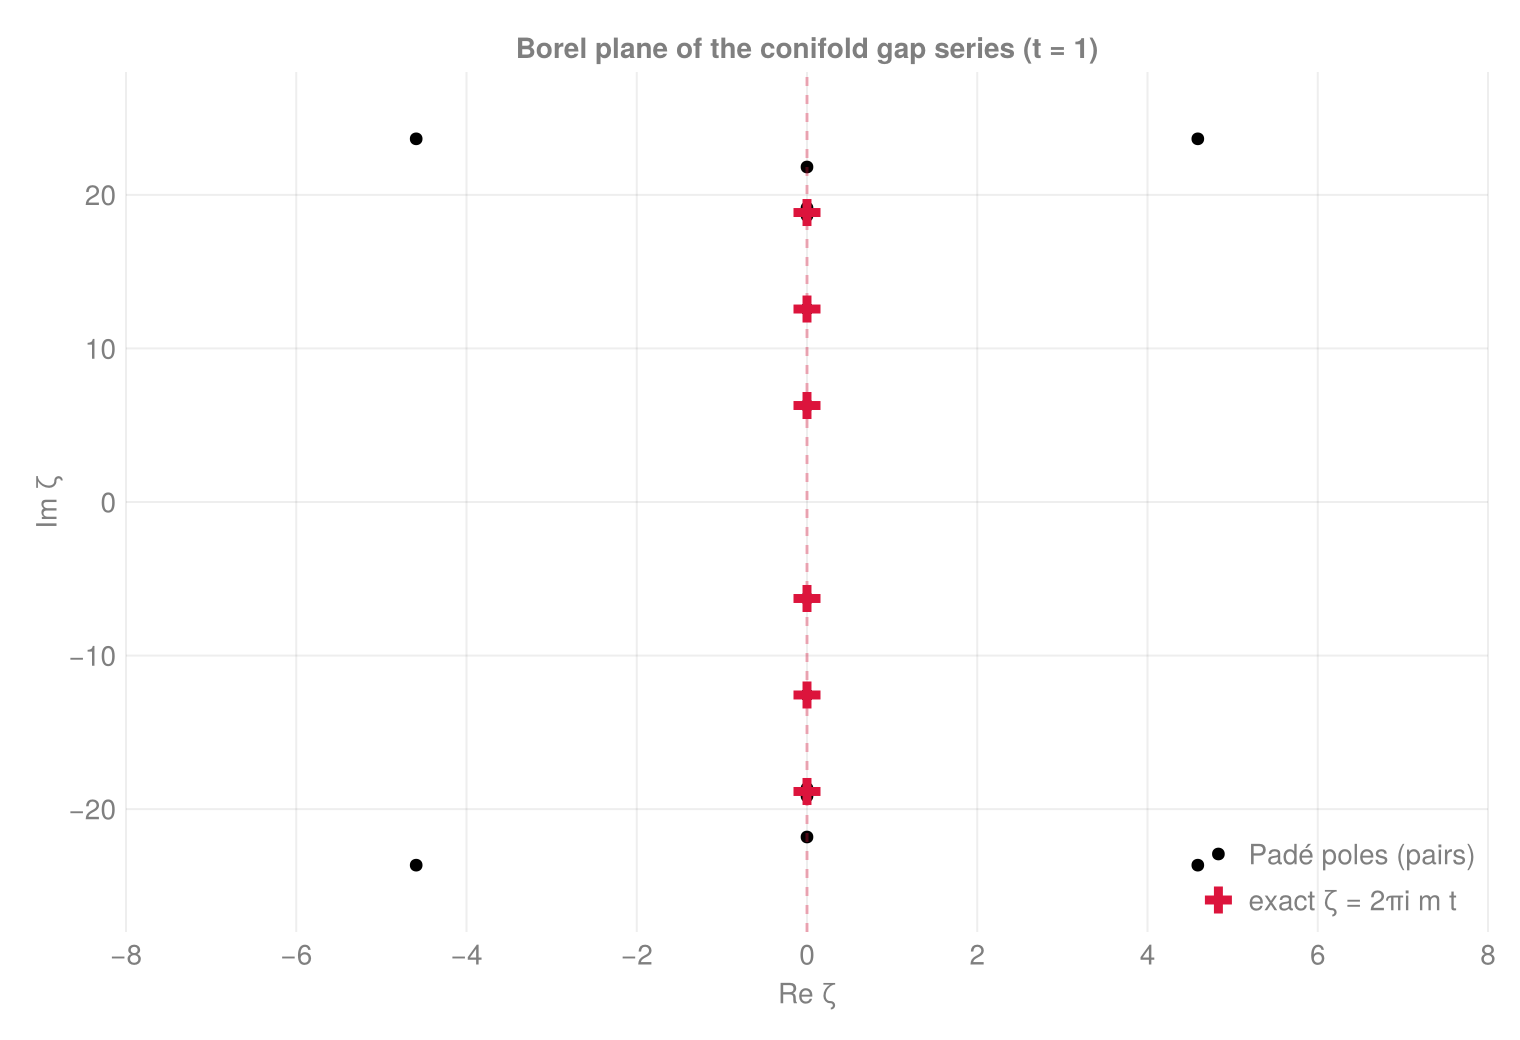

In [8]:
fig = Figure(size = (760, 520))
ax = Axis(fig[1, 1]; xlabel = "Re ζ", ylabel = "Im ζ",
          title = "Borel plane of the conifold gap series (t = 1)")
exact = ComplexF64.(conifold_gap_actions(; t = 1, mmax = 3))
scatter!(ax, real.(p), imag.(p); markersize = 9, color = :black,
         label = "Padé poles (pairs)")
scatter!(ax, real.(exact), imag.(exact); markersize = 18, marker = :cross,
         color = :crimson, label = "exact ζ = 2πi m t")
vlines!(ax, [0.0]; color = (:crimson, 0.35), linestyle = :dash)
axislegend(ax; position = :rb)
xlims!(ax, -8, 8);  ylims!(ax, -28, 28)
fig

The poles lie on the imaginary axis, at $2\pi i m$, and the imaginary axis is
therefore a **Stokes ray**: the Laplace integral that resums the series runs into
them. Off that ray the series is Borel summable, which is section 6; on it the sum
is ambiguous by an exponentially small amount, which is section 7.

## 6. Summation

Along a non-Stokes direction, Borel-Laplace resummation gives an actual function of
$\lambda$ whose asymptotic expansion is the genus expansion we started from:

$$ s(F)(\lambda) \;=\; \int_0^{\infty} e^{-\zeta/\lambda}\, \mathcal{B}[F](\zeta)\, d\zeta . $$

Because we know $\mathcal{B}[F]$ in closed form, this is a rare situation: we can
compare the package's *approximate* route (truncate at 20 genus terms, Padé the
Borel series, integrate) against the *exact* answer (integrate the closed form
numerically), with no Padé anywhere on the exact side. That is the strongest
end-to-end check of the summation stack available.

In [9]:
B = borel(gap20)
r = pade(B; reduce = true)

sig(x, n = 12) = string(round(Float64(x); sigdigits = n))

println(" λ       Borel-Padé-Laplace       exact quadrature         rel. error")
for λ in (0.2, 0.4, 0.7, 1.0)
    approx = real(laplace_sum(B, r, λ))
    ex, _ = quadgk(ζ -> exp(-ζ / λ) * conifold_gap_borel(ζ), 0.0, Inf; rtol = 1e-13)
    println(rpad(λ, 8), rpad(sig(approx), 25), rpad(sig(ex), 25),
            sig(abs(approx - ex) / abs(ex), 3))
end

 λ       Borel-Padé-Laplace       exact quadrature         rel. error
0.2     -0.000165121577047       

-0.000165121577047       4.87e-17
0.4     -0.000643644155774       -0.000643644155774       1.26e-16
0.7     -0.00185628421717        -0.00185628421717        5.14e-17
1.0     -0.00351738950422        -0.00351738950422        6.99e-17


## 7. Stokes jumps: where the D-branes are

Cross the imaginary axis and the resummation jumps. The two lateral sums differ by
the contour picked up around the poles, and with the package's convention
$\mathrm{disc} = s_+ - s_-$ a Laurent tail
$c_2/(\zeta-\zeta_m)^2 + c_1/(\zeta-\zeta_m)$ contributes

$$ \mathrm{disc}_m \;=\; \left[\frac{2\pi i\, c_2}{\lambda} - 2\pi i\, c_1\right]
   e^{-\zeta_m/\lambda} . $$

Expanding the closed form near $\zeta_m = 2\pi i m t$ gives
$c_2 = -t/(2\pi i m)$ and $c_1 = -1/(4\pi^2 m^2)$, hence the exact prediction

$$ \mathrm{disc} \;=\; \sum_{m \ge 1}
   \left[\frac{-t}{m\lambda} + \frac{i}{2\pi m^2}\right] e^{-2\pi i m t/\lambda} . $$

Read the physics off it. The exponential $e^{-2\pi i m t/\lambda}$ is a
nonperturbative effect whose action is $2\pi i$ times $m$ times the period $t$:
a D-brane wrapping the shrinking cycle $m$ times. The $1/m^2$ is the universal
multicover weight of a *single* underlying state, which is right, since the
resolved conifold has exactly one BPS state ($n^0_1 = 1$). The $1/\lambda$ term,
absent for a simple pole, is the one-loop factor that a double pole encodes.
Nothing here was fitted: `conifold_gap_stokes_data` returns the Laurent
coefficients analytically.

In [10]:
# On the ray θ = π/2 we need Re(e^{iθ}/λ) > 0, so take λ = i·ℓ with ℓ > 0.
# Then e^{-ζ_m/λ} = e^{-2πmt/ℓ}: real, and geometrically suppressed in m.
t = 1
println(" ℓ       Im disc (numerical)      Im disc (exact Laurent)  rel. error")
for ℓ in (0.4, 0.6, 0.9, 1.3)
    λ = im * ℓ
    d = stokes_discontinuity(B, r, λ; θ = π / 2, tilt = 0.2)
    pred = sum(1:8) do m
        sd = conifold_gap_stokes_data(m; t)
        (2π * im * sd.double / λ - 2π * im * sd.residue) * exp(-sd.action / λ)
    end
    println(rpad(ℓ, 8), rpad(sig(imag(d)), 25), rpad(sig(imag(pred)), 25),
            sig(abs(d - pred) / abs(pred), 3))
end

 ℓ       Im disc (numerical)      Im disc (exact Laurent)  rel. error
0.4     4.0073927301e-7          

4.0073927301e-7          1.35e-14
0.6     5.17062503852e-5         5.17062503852e-5         1.6e-14
0.9     0.00118069145744         0.00118069145744         1.72e-12
1.3     

0.00741777542084         0.00741777542083         6.71e-13


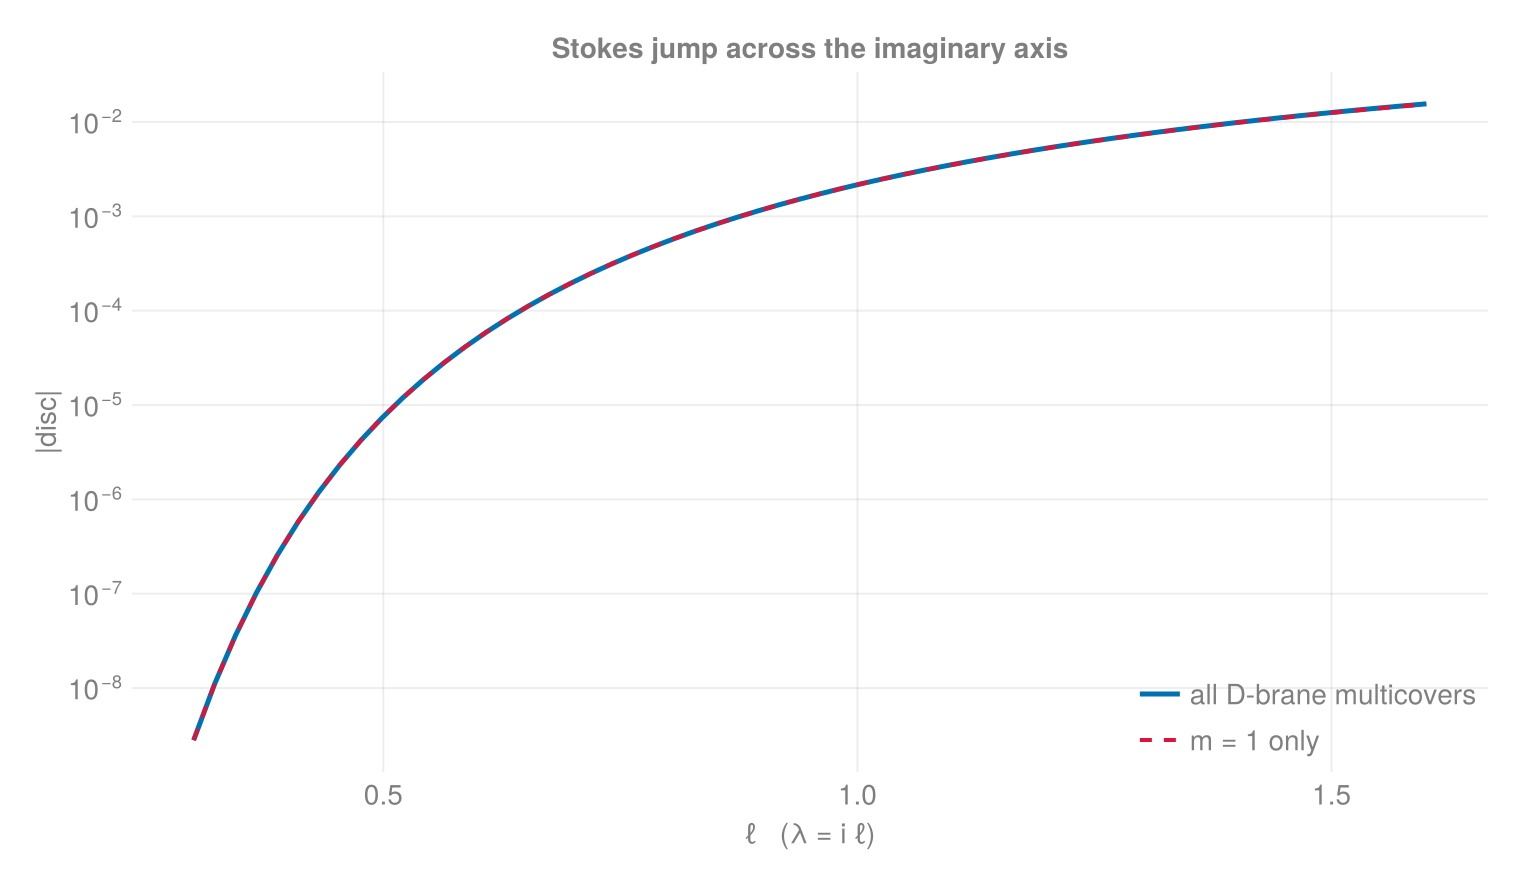

In [11]:
# The one-instanton term alone, against the full jump: the m ≥ 2 branes are the
# difference, and they matter more as ℓ grows.
ℓs = range(0.30, 1.60; length = 60)
full = Float64[]
one  = Float64[]
for ℓ in ℓs
    λ = im * ℓ
    push!(full, abs(stokes_discontinuity(B, r, λ; θ = π / 2, tilt = 0.2)))
    sd = conifold_gap_stokes_data(1; t = 1)
    push!(one, abs((2π * im * sd.double / λ - 2π * im * sd.residue) *
                   exp(-sd.action / λ)))
end

fig2 = Figure(size = (760, 440))
ax2 = Axis(fig2[1, 1]; xlabel = "ℓ   (λ = i ℓ)", ylabel = "|disc|", yscale = log10,
           title = "Stokes jump across the imaginary axis")
lines!(ax2, ℓs, full; linewidth = 2.5, label = "all D-brane multicovers")
lines!(ax2, ℓs, one; linewidth = 2, linestyle = :dash, color = :crimson,
       label = "m = 1 only")
axislegend(ax2; position = :rb)
fig2

## 8. The resolved conifold: a lattice of branes

Away from the conifold point the picture is richer. Keeping $t$ finite and real,
the Borel singularities of the resolved conifold move off the imaginary axis onto
the **real** axis, at $\zeta = 2\pi m t$: the D2-branes wrapping the $\mathbb{P}^1$
$m$ times. There is a second quantum number, the D0-brane charge, which shifts the
action by multiples of $4\pi^2 i$. Pinching the poles of $1/(2\sin(x/2))^2$ at
$x = 2\pi m$ against the poles of the $d$-sum's geometric factor at
$x = \zeta/(t + 2\pi i n)$ places the whole lattice at

$$ \zeta_{m,n} \;=\; 2\pi m\,(t + 2\pi i\, n), \qquad m \ne 0,\ n \in \mathbb{Z} . $$

This is the setting of the work of Alim and collaborators: the Stokes jumps across
these rays are the **Donaldson-Thomas invariants** of $X$, and the resurgent
structure of the free energy is a way of computing them from Gromov-Witten data.
The $n=0$ tower is what 20 genus terms can see; the $n \ne 0$ shifts sit at
$4\pi^2 \approx 39.5$ and are far outside the reach of this truncation.

*One caveat.* The lattice above is derived in this package by the pinching
argument just described, and only its $n = 0$ tower has been verified numerically.
Whether the $n \ne 0$ shifts run over all integers or only over multiples of $m$
has not been checked against the literature. It is flagged as open in the
package's `PLANNING/references.md`.

In [12]:
rc20 = resolved_conifold_series(20; Q = exp(-big(1.0)))    # t = 1
prc = ComplexF64.(borel_pade_poles(rc20; reduce = true))
right = sort(filter(z -> real(z) > 0, prc); by = abs)

println("nearest Padé poles to the right of the origin:")
for z in right[1:4]
    println("   ", z)
end
println("\nmidpoint of the first pair : ", (real(right[1]) + real(right[2])) / 2,
        "     exact 2πt = ", 2π)
println("midpoint of the second pair: ", (real(right[3]) + real(right[4])) / 2,
        "     exact 4πt = ", 4π)

nearest Padé poles to the right of the origin:


   6.283185299884933 - 1.8938756582420115e-10im
   6.28318531447424 + 1.8938796685674418e-10im
   12.560527867789888 - 0.0im
   12.572311789476503 - 0.0im

midpoint of the first pair : 6.283185307179586     exact 2πt = 6.283185307179586
midpoint of the second pair: 12.566419828633196     exact 4πt = 12.566370614359172


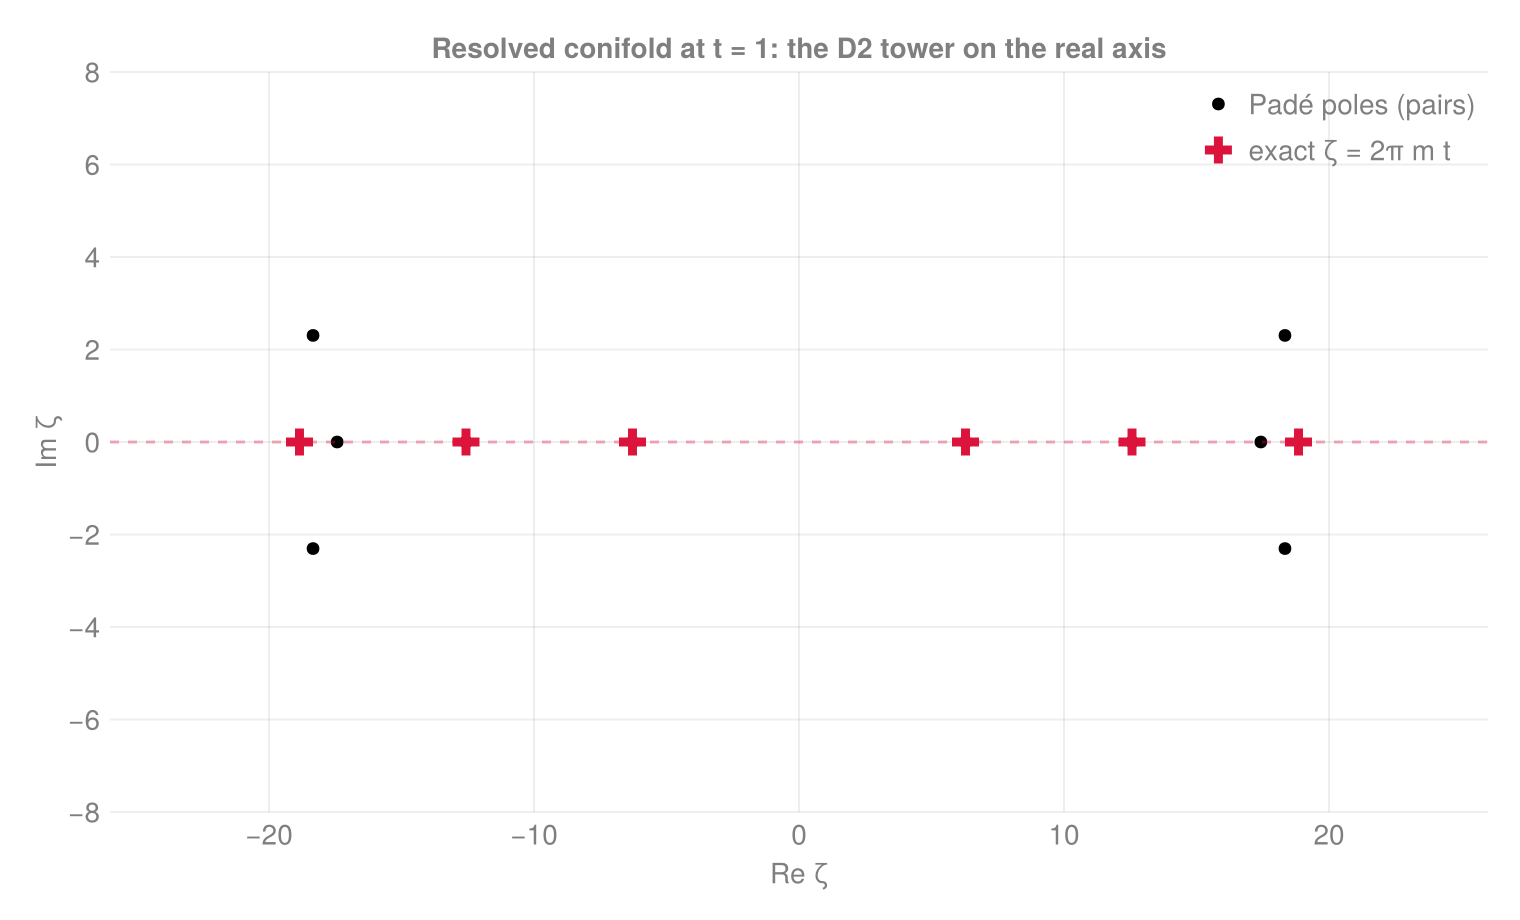

In [13]:
fig3 = Figure(size = (760, 460))
ax3 = Axis(fig3[1, 1]; xlabel = "Re ζ", ylabel = "Im ζ",
           title = "Resolved conifold at t = 1: the D2 tower on the real axis")
lat = ComplexF64.(resolved_conifold_actions(; t = 1.0, mmax = 3, nmax = 0))
scatter!(ax3, real.(prc), imag.(prc); markersize = 9, color = :black,
         label = "Padé poles (pairs)")
scatter!(ax3, real.(lat), imag.(lat); markersize = 18, marker = :cross,
         color = :crimson, label = "exact ζ = 2π m t")
hlines!(ax3, [0.0]; color = (:crimson, 0.35), linestyle = :dash)
axislegend(ax3; position = :rt)
xlims!(ax3, -26, 26);  ylims!(ax3, -8, 8)
fig3

## 9. What this notebook does not do, and why

`Resurgence.jl` will not gain a topological-string *generator*. No topological
recursion, no holomorphic-anomaly recursion, no Gromov-Witten or Gopakumar-Vafa
computation. The reason is reuse rather than difficulty: such an engine shares
nothing with the series layer this package is built around, and it would turn an
analysis tool into a coefficient factory whose output nobody could check.

The package does instead what this notebook showed: take a genus expansion produced
anywhere at all and extract its nonperturbative content, with an exact identity
gating every step. The two geometries here were chosen because their
$F_g$ are closed forms, so nothing had to be imported. For a geometry without a
closed form (local $\mathbb{P}^2$ is the canonical next example) the $F_g$ would
come in as an imported table and the rest of this notebook would run unchanged.

Pointers into the package:

| What | Where |
|---|---|
| The free energies and Borel data | `src/topological_string.jl`, with a convention ledger at the top |
| Every identity above, as a test | `test/test_topological_string.jl` |
| The Borel-Padé-Laplace pipeline | `src/borel.jl`, `src/pade.jl`, `src/laplace.jl` |
| Sign conventions for `disc` and Stokes constants | the ledger at the top of `src/alien.jl` |
| Sources | `PLANNING/references.md`, keys `[GV98]`, `[HKQ07]`, `[PS09]`, `[ASTT22]`, `[Alim24]` |